In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

GPU available: True
Device: Tesla T4


# Arabic Readability Classification Using Deep Learning

## Experiment Objective

This experiment extends the project's earlier Linear SVM readability classification work by evaluating **contextual AraBERT representations** on the same prepared, four-level BAREC classification task. Unlike SVM with TF-IDF, AraBERT learns contextual representations of Arabic sentences [1], [2]. Whether this approach performs better must be established experimentally; it is not assumed.

Three AraBERTv0.2 objectives are evaluated **independently** with no predefined reference model:

1. **Weighted Cross-Entropy** (categorical classification)
2. **CORAL** (ordinal classification)
3. **MSE Regression** (continuous ordinal scoring)

All use the prepared `merged_4_level` train/dev/test splits. The model is selected by **development-set Quadratic Weighted Kappa (QWK)**; only the selected model is evaluated on the test split. Results for the project's four-level scheme must not be treated as directly comparable to published BAREC results on 19 or 5 levels [3], [5].

## 1. Data Loading



In [ ]:
import pandas as pd
from pathlib import Path

# ZIP uploaded to Colab Files (/content)
!unzip -oq "/content/BAREC_prepared_datasets.zip" -d "/content/barec_input"
merged_dir = next(Path("/content/barec_input").rglob("merged_4_level"))

train_4 = pd.read_csv(merged_dir / "train.csv")
val_4 = pd.read_csv(merged_dir / "dev.csv")
test_4 = pd.read_csv(merged_dir / "test.csv")

TEXT_COLUMN = "Word"
LABEL_COLUMN = "Readability_Level_4"

for name, df in [("Train", train_4), ("Dev", val_4), ("Test", test_4)]:
    assert {TEXT_COLUMN, LABEL_COLUMN}.issubset(df.columns), f"Missing columns in {name}"
    assert df[[TEXT_COLUMN, LABEL_COLUMN]].notna().all().all(), f"Missing values in {name}"
    assert df[LABEL_COLUMN].isin([1, 2, 3, 4]).all(), f"Invalid labels in {name}"
    assert df[TEXT_COLUMN].map(lambda x: isinstance(x, str) and bool(x.strip())).all(), f"Empty text in {name}"
    print(f"{name}: {df.shape}")

Train: (54845, 20)
Dev: (7310, 20)
Test: (7286, 20)


## 2. Model Input Preparation

This section prepares the already processed text for AraBERT. Only the label indices and model inputs are adapted; **no dataset cleaning** is performed.

### 2.1 Libraries and Training Parameters

This section imports the required libraries and defines the training configuration for the three AraBERT-based models. Consistent hyperparameter settings are used across all models to support a controlled comparison of their learning objectives [1], [2], [7].

In [ ]:
%pip -q install "transformers>=4.46,<5" "accelerate>=1,<2" "datasets>=3,<5" coral-pytorch pandas numpy scikit-learn seaborn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 67.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 75.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import inspect
import json
import math
import os
import random
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from datasets import Dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
)
from transformers import (
    AutoConfig,
    AutoModel,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)
from transformers.modeling_outputs import SequenceClassifierOutput
from coral_pytorch.layers import CoralLayer
from coral_pytorch.losses import coral_loss

warnings.filterwarnings("ignore", category=FutureWarning)

MODEL_NAME = "aubmindlab/bert-base-arabertv02"
TEXT_COLUMN = "Word"
LABEL_COLUMN = "Readability_Level_4"
NUM_LABELS = 4
MAX_LENGTH = 128
SEED = 42
LEARNING_RATE = 2e-5
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 2
NUM_EPOCHS = 3
WEIGHT_DECAY = 0.01
WARMUP_FRACTION = 0.10

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if not torch.cuda.is_available():
    print("Warning: transformer fine-tuning on CPU will be very slow. Select a GPU runtime in Colab.")


Device: cuda


### 2.2 Four-Level Label Mapping

Readability levels `1–4` are mapped to model indices `0–3` for training. Text and dataset split membership stay unchanged.

In [ ]:
def prepare_dl_split(df):
    prepared = df[[TEXT_COLUMN, LABEL_COLUMN]].copy().reset_index(drop=True)
    prepared["labels"] = prepared[LABEL_COLUMN].astype(int) - 1
    if not prepared["labels"].between(0, NUM_LABELS - 1).all():
        raise ValueError("Labels must map to 0..3.")
    return prepared[[TEXT_COLUMN, "labels"]]

train_dl = prepare_dl_split(train_4)
val_dl = prepare_dl_split(val_4)
test_dl = prepare_dl_split(test_4)
print("Train / Dev / Test:", len(train_dl), len(val_dl), len(test_dl))

Train / Dev / Test: 54845 7310 7286


### 2.3 AraBERT Tokenization

Use the tokenizer corresponding to `aubmindlab/bert-base-arabertv02`. A maximum of 128 tokens and dynamic batch padding follow the original experiment; no TF-IDF is used [1]. Longer sequences are truncated at 128 tokens.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    return tokenizer(batch[TEXT_COLUMN], truncation=True, max_length=MAX_LENGTH)

def to_tokenized_dataset(df):
    dataset = Dataset.from_pandas(df, preserve_index=False)
    return dataset.map(
        tokenize_batch, batched=True,
        remove_columns=[TEXT_COLUMN], desc="Tokenizing"
    )

train_ds = to_tokenized_dataset(train_dl)
val_ds = to_tokenized_dataset(val_dl)
test_ds = to_tokenized_dataset(test_dl)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/381 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizing:   0%|          | 0/54845 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/7310 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/7286 [00:00<?, ? examples/s]

## 3. Evaluation Metrics

All three models are measured using **Accuracy**, **Macro-F1**, **QWK**, **MAE**, **RMSE**, and **Within-One Accuracy** (`|prediction − true level| ≤ 1`). QWK is the model-selection metric because it penalizes errors between distant ordered readability levels more heavily [3].

In [ ]:
def ordinal_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "qwk": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "within_one": np.mean(np.abs(y_true - y_pred) <= 1),
    }

def unpack_logits(predictions):
    return predictions[0] if isinstance(predictions, tuple) else predictions

def compute_cross_entropy_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(unpack_logits(logits), axis=-1)
    return ordinal_metrics(labels, predictions)

def coral_logits_to_labels(logits):
    probabilities = torch.sigmoid(torch.as_tensor(logits)).cpu().numpy()
    return (probabilities > 0.5).sum(axis=1).astype(int)

def compute_coral_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = coral_logits_to_labels(unpack_logits(logits))
    return ordinal_metrics(labels, predictions)

def regression_outputs_to_labels(outputs):
    raw_scores = np.asarray(outputs).reshape(-1)
    return np.clip(np.rint(raw_scores), 0, NUM_LABELS - 1).astype(int)

def compute_mse_metrics(eval_pred):
    outputs, labels = eval_pred
    raw_scores = np.asarray(unpack_logits(outputs)).reshape(-1)
    predictions = regression_outputs_to_labels(raw_scores)
    metrics = ordinal_metrics(labels, predictions)
    metrics["raw_mae"] = mean_absolute_error(labels, raw_scores)
    metrics["raw_rmse"] = np.sqrt(mean_squared_error(labels, raw_scores))
    return metrics


## 4. Shared Training Configuration

All models retain the original AraBERT checkpoint, learning rate (`2e-5`), training batch size (`16`, gradient accumulation `2`), three epochs, weight decay (`0.01`), and 10% warm-up. Each run selects its best checkpoint by development QWK; the test set is not used to choose a model [2], [7].

In [ ]:
updates_per_epoch = math.ceil(
    len(train_ds) / (TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
)
total_update_steps = updates_per_epoch * NUM_EPOCHS
warmup_steps = round(WARMUP_FRACTION * total_update_steps)

def make_training_args(output_dir):
    parameters = inspect.signature(TrainingArguments.__init__).parameters
    kwargs = dict(
        output_dir=output_dir,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        num_train_epochs=NUM_EPOCHS,
        weight_decay=WEIGHT_DECAY,
        warmup_steps=warmup_steps,
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="qwk",
        greater_is_better=True,
        save_total_limit=1,
        report_to="none",
        fp16=torch.cuda.is_available(),
        seed=SEED,
        data_seed=SEED,
    )
    if "eval_strategy" in parameters:
        kwargs["eval_strategy"] = "epoch"
    else:
        kwargs["evaluation_strategy"] = "epoch"
    return TrainingArguments(**kwargs)

print("Updates per epoch:", updates_per_epoch)
print("Total update steps:", total_update_steps)
print("Warm-up steps:", warmup_steps)


Updates per epoch: 1714
Total update steps: 5142
Warm-up steps: 514



### 4.1 Training Parameters and Justification

The following parameters define the shared configuration used to fine-tune the three AraBERT-based models. Consistent settings are maintained to enable a controlled comparison of the different learning objectives.

The initial parameter values are informed by established BERT fine-tuning practices [2] and research on training stability [8]. Their suitability for the BAREC four-level task can be further investigated through hyperparameter tuning.

#### Model and Input Parameters

| Parameter | Value | Description and Justification |
|---|---|---|
| `MODEL_NAME` | `aubmindlab/bert-base-arabertv02` | Specifies the pretrained AraBERT checkpoint. AraBERT is designed for Arabic language understanding and provides contextual text representations [1]. |
| `NUM_LABELS` | 4 | Represents the four ordered readability levels used in this experiment, following the project's merged BAREC label scheme [5]. |
| `MAX_LENGTH` | 128 | Sets the maximum input sequence length in tokens. This value offers a practical balance between contextual information and computational cost, although longer inputs may be truncated [2]. |
| `SEED` | 42 | Controls random initialization and other stochastic training operations to support reproducibility. The number 42 is a fixed experimental choice, not a theoretically optimal value [8]. |

#### Optimization Parameters

| Parameter | Value | Description and Justification |
|---|---|---|
| `LEARNING_RATE` | 2e-5 | Controls how much the model weights change during optimization. Devlin et al. recommend exploring learning rates of 2e-5, 3e-5, and 5e-5 for BERT fine-tuning [2]. |
| `TRAIN_BATCH_SIZE` | 16 | Processes 16 training examples per device in each forward/backward pass. Batch sizes of 16 and 32 are among the recommended BERT fine-tuning candidates [2]. |
| `EVAL_BATCH_SIZE` | 32 | Processes 32 examples per device during evaluation. Since gradient computation is unnecessary, a larger evaluation batch can improve efficiency. This is a practical configuration choice [9]. |
| `GRADIENT_ACCUMULATION_STEPS` | 2 | Accumulates gradients over two batches before updating the model weights. With one GPU, this produces an effective training batch size of 32, reducing memory requirements compared with processing all 32 examples simultaneously [9]. |
| `NUM_EPOCHS` | 3 | Defines three complete passes through the training dataset. BERT fine-tuning experiments commonly explore 2, 3, or 4 epochs [2]. |
| `WEIGHT_DECAY` | 0.01 | Applies regularization to discourage excessively large weights and reduce overfitting. A value of 0.01 is used in established BERT optimization implementations [8], [10]. |
| `WARMUP_FRACTION` | 0.10 | Gradually increases the learning rate during the first 10% of optimizer updates before the learning-rate schedule decays. This strategy is used in BERT fine-tuning research to support training stability [8]. |

#### Training and Checkpoint Configuration

| Parameter | Value | Description |
|---|---|---|
| `eval_strategy` | epoch | Evaluates performance on the development set after each epoch. |
| `save_strategy` | epoch | Saves a model checkpoint after each epoch. |
| `logging_strategy` | epoch | Records training information after each epoch. |
| `load_best_model_at_end` | True | Restores the best checkpoint after training. |
| `metric_for_best_model` | qwk | Selects the checkpoint using Quadratic Weighted Kappa, which accounts for differences between ordered readability levels [3]. |
| `greater_is_better` | True | Indicates that higher QWK values represent better performance. |
| `save_total_limit` | 1 | Limits checkpoint storage to reduce disk usage while preserving the best checkpoint. |
| `fp16` | GPU-dependent | Enables mixed-precision training when CUDA is available to improve computational efficiency. |
| `seed` / `data_seed` | 42 | Sets consistent random seeds for training and data operations to improve reproducibility. |

The checkpoint-management and training arguments follow the Hugging Face Transformers implementation [9].

**Hyperparameter Tuning:** These settings establish the initial training configuration. Each model can subsequently be evaluated with alternative hyperparameter values using the development set. The test set remains reserved for final evaluation.


## 5. Model 1 — AraBERTv0.2 + Weighted Cross-Entropy

### 5.1 Model Rationale

Cross-Entropy learns one score per readability class, without explicitly representing the order of the four levels. Training-split inverse-frequency class weights reduce the effect of imbalance. This is **one of three evaluated approaches**, not an assumed reference or default winner [2], [5].

### 5.2 Training and Development Evaluation

In [ ]:

from pathlib import Path

def find_initial_checkpoint(output_dir):
    output_dir = Path(output_dir)

    checkpoints = [
        p for p in output_dir.glob("checkpoint-*")
        if p.is_dir()
    ]

    if not checkpoints:
        raise FileNotFoundError(
            f"No checkpoints found in {output_dir}"
        )

    return max(
        checkpoints,
        key=lambda p: int(p.name.split("-")[-1])
    )


In [ ]:
class_counts = np.bincount(train_dl["labels"], minlength=NUM_LABELS)
class_weights = len(train_dl) / (NUM_LABELS * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

display(pd.DataFrame({
    "level": np.arange(1, NUM_LABELS + 1),
    "training_count": class_counts,
    "cross_entropy_weight": class_weights,
}))

class WeightedCrossEntropyTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_function = nn.CrossEntropyLoss(
            weight=class_weights_tensor.to(outputs.logits.device)
        )
        loss = loss_function(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

set_seed(SEED)
cross_entropy_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
)

cross_entropy_trainer = WeightedCrossEntropyTrainer(
    model=cross_entropy_model,
    args=make_training_args("./results_weighted_cross_entropy"),
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_cross_entropy_metrics,
)

cross_entropy_trainer.train()
cross_entropy_validation_metrics = cross_entropy_trainer.evaluate()
cross_entropy_validation_metrics


,level,training_count,cross_entropy_weight
0,1,10396,1.318897
1,2,17908,0.765649
2,3,14570,0.941060
3,4,11971,1.145372


model.safetensors:   0%|          | 0.00/543M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One
1,0.851600,0.723746,0.688919,0.674385,0.756089,0.398906,0.766965,0.919015
2,0.612300,0.687183,0.717921,0.711436,0.782669,0.354172,0.713654,0.933379
3,0.486600,0.728210,0.718878,0.715107,0.783272,0.349795,0.704975,0.936252


{'eval_loss': 0.7282096147537231,
 'eval_accuracy': 0.7188782489740082,
 'eval_macro_f1': 0.7151073592289087,
 'eval_qwk': 0.7832718773748425,
 'eval_mae': 0.3497948016415869,
 'eval_rmse': 0.7049754776420293,
 'eval_within_one': 0.9362517099863201,
 'eval_runtime': 5.4262,
 'eval_samples_per_second': 1347.162,
 'eval_steps_per_second': 42.202,
 'epoch': 3.0}


### 5.3 Initial Training Findings

The AraBERT model with Weighted Cross-Entropy demonstrated progressive improvement across the three training epochs.

**Development Set Results (Epoch 3):**

| Metric | Result |
|---|---:|
| Accuracy | 0.7189 |
| Macro-F1 | 0.7151 |
| QWK | 0.7833 |
| MAE | 0.3498 |
| RMSE | 0.7050 |
| Within-One Accuracy | 0.9363 |

**Findings:**

- **Accuracy (71.89%):** Approximately 72% of the predictions matched the correct readability level exactly.
- **Macro-F1 (71.51%):** Indicates reasonably balanced overall classification performance across the four levels, although individual class performance requires further examination.
- **QWK (0.7833):** Indicates substantial agreement between predicted and actual ordinal labels, accounting for the severity of disagreements. This is the primary metric for model selection.
- **MAE (0.3498):** Predictions differed from the actual level by approximately 0.35 levels on average.
- **RMSE (0.7050):** Reflects the magnitude of prediction errors, with greater sensitivity to larger mistakes.
- **Within-One Accuracy (93.63%):** Most predictions were either correct or within one adjacent readability level.

**Training Observation:**

Training loss decreased consistently from 0.8516 to 0.4866. However, validation loss reached its minimum at Epoch 2 (0.6872) before increasing to 0.7282 at Epoch 3.

Despite this increase, Epoch 3 achieved the highest QWK (0.7833), compared with 0.7827 at Epoch 2. This suggests a possible early indication of overfitting, although the small QWK difference does not establish a meaningful performance advantage.

**Conclusion:**

The initial configuration provides promising ordinal classification performance. A limited hyperparameter tuning experiment will be conducted to investigate whether an alternative fine-tuning configuration improves development QWK without substantially increasing computational cost.


### 5.4 Initial Training Confusion Matrix

The confusion matrix shows initial-training predictions on the development set. Rows represent actual readability levels and columns represent predicted levels. The diagonal shows correct predictions; off-diagonal cells show errors, including how far predictions are from the true level.

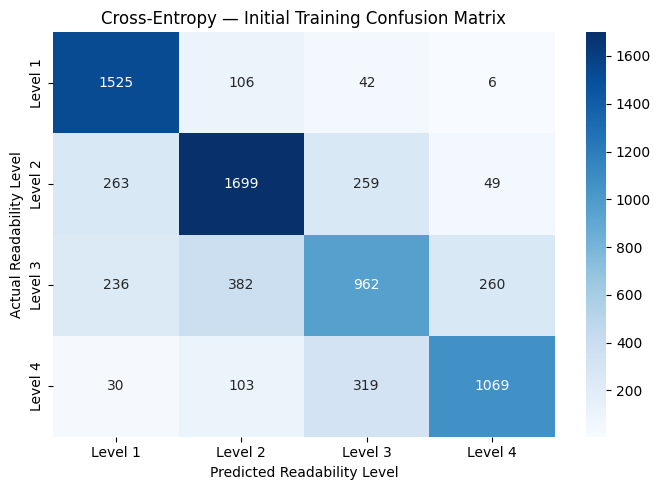

In [ ]:

# 5.4 Initial Training Confusion Matrix

from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch

# Load the best checkpoint from initial training
checkpoint = find_initial_checkpoint(
    "./results_weighted_cross_entropy"
)

model = AutoModelForSequenceClassification.from_pretrained(
    str(checkpoint)
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model.to(device)
model.eval()

# Prepare development data
loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    collate_fn=data_collator
)

y_true, y_pred = [], []

# Generate predictions without Trainer
with torch.inference_mode():
    for batch in loader:
        labels = batch.pop("labels")

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
        }

        logits = model(**inputs).logits
        predictions = torch.argmax(logits, dim=-1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Convert labels from 0-3 to 1-4
y_true = np.array(y_true) + 1
y_pred = np.array(y_pred) + 1

# Plot Confusion Matrix
cm = confusion_matrix(
    y_true, y_pred, labels=[1, 2, 3, 4]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Level 1", "Level 2", "Level 3", "Level 4"],
    yticklabels=["Level 1", "Level 2", "Level 3", "Level 4"]
)

plt.title("Cross-Entropy — Initial Training Confusion Matrix")
plt.xlabel("Predicted Readability Level")
plt.ylabel("Actual Readability Level")
plt.tight_layout()
plt.show()

# Release memory
model.to("cpu")
del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()


### 5.5 Hyperparameter Tuning Using Grid Search

A computationally constrained grid search is conducted to optimize the AraBERT Weighted Cross-Entropy model.

#### Search Space and Justification

The hyperparameter search space was defined based on established BERT fine-tuning recommendations [2] and training configurations reported in previous BAREC Shared Task studies.

Learning rates of 2e-5 and 3e-5 and training durations of 2 and 3 epochs were evaluated. These values fall within the ranges recommended by Devlin et al. (2019), while the batch size of 16 is consistent with configurations used in BAREC systems such as !MSA and ZAI.

The search space was intentionally restricted to four configurations to balance computational cost and systematic parameter evaluation. Model selection was based on development QWK, following the primary evaluation metric of BAREC.

The resulting configuration represents the best setting among the evaluated candidates, rather than a globally optimal hyperparameter configuration.


#### Model Selection

Each configuration is evaluated on the development set using Quadratic Weighted Kappa (QWK).

The best-performing checkpoint is selected using development QWK, and the highest-scoring configuration is retained for comparison with the other deep learning approaches.

The test set is reserved for final evaluation.

In [ ]:
import gc
import shutil
from itertools import product
from pathlib import Path

# Reuse the completed initial experiment
initial_metrics = dict(cross_entropy_validation_metrics)
best_qwk = float(initial_metrics["eval_qwk"])
best_config = (LEARNING_RATE, NUM_EPOCHS)
best_metrics = initial_metrics

best_dir = Path("/content/ce_grid_best_tuned")

def result_row(lr, epochs, metrics, source):
    return {
        "learning_rate": lr,
        "epochs": epochs,
        "accuracy": metrics["eval_accuracy"],
        "macro_f1": metrics["eval_macro_f1"],
        "qwk": metrics["eval_qwk"],
        "mae": metrics["eval_mae"],
        "rmse": metrics["eval_rmse"],
        "within_one": metrics["eval_within_one"],
        "source": source
    }

results = [
    result_row(
        LEARNING_RATE, NUM_EPOCHS,
        initial_metrics, "Initial training"
    )
]

# Release GPU memory before the search
cross_entropy_trainer.model.to("cpu")
cross_entropy_trainer.optimizer = None
cross_entropy_trainer.lr_scheduler = None
gc.collect()
torch.cuda.empty_cache()

# Define the grid (2 × 2)
grid = list(product(
    [2e-5, 3e-5],
    [2, 3]
))

for lr, epochs in grid:

    # Skip the already evaluated configuration
    if (lr, epochs) == (LEARNING_RATE, NUM_EPOCHS):
        continue

    print(f"\nTraining: LR={lr}, Epochs={epochs}")

    set_seed(SEED)

    args = make_training_args(
        f"/content/ce_grid_lr{lr}_ep{epochs}"
    )
    args.learning_rate = lr
    args.num_train_epochs = epochs
    args.warmup_steps = round(
        WARMUP_FRACTION * updates_per_epoch * epochs
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=NUM_LABELS
    )

    trainer = WeightedCrossEntropyTrainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_cross_entropy_metrics
    )

    trainer.train()
    metrics = trainer.evaluate()

    results.append(
        result_row(lr, epochs, metrics, "Grid search")
    )

    # Keep the configuration with the highest Dev QWK
    if metrics["eval_qwk"] > best_qwk:
        best_qwk = float(metrics["eval_qwk"])
        best_config = (lr, epochs)
        best_metrics = dict(metrics)

        shutil.rmtree(best_dir, ignore_errors=True)
        trainer.model.save_pretrained(
            str(best_dir),
            safe_serialization=True
        )

    # Free memory between trials
    trainer.optimizer = None
    trainer.lr_scheduler = None
    trainer.model.to("cpu")
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()

# Display grid search results
ce_grid_results = pd.DataFrame(results).sort_values(
    "qwk", ascending=False
).reset_index(drop=True)

display(ce_grid_results)

# Restore the best Cross-Entropy configuration
SELECTED_CE_LR, SELECTED_CE_EPOCHS = best_config

if best_config != (LEARNING_RATE, NUM_EPOCHS):

    del cross_entropy_trainer, cross_entropy_model
    gc.collect()

    cross_entropy_model = (
        AutoModelForSequenceClassification.from_pretrained(
            str(best_dir)
        )
    )

    selected_args = make_training_args(
        "/content/ce_grid_selected"
    )
    selected_args.learning_rate = SELECTED_CE_LR
    selected_args.num_train_epochs = SELECTED_CE_EPOCHS
    selected_args.warmup_steps = round(
        WARMUP_FRACTION * updates_per_epoch * SELECTED_CE_EPOCHS
    )

    cross_entropy_trainer = WeightedCrossEntropyTrainer(
        model=cross_entropy_model,
        args=selected_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_cross_entropy_metrics
    )

else:
    cross_entropy_trainer.model.to(DEVICE)

cross_entropy_validation_metrics = best_metrics

print("\nBest CE Configuration:", best_config)
print("Best Validation QWK:", round(best_qwk, 6))



Training: LR=2e-05, Epochs=2


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One
1,0.836000,0.710263,0.692339,0.679795,0.760607,0.392202,0.758085,0.922161
2,0.608100,0.689658,0.713269,0.708053,0.781493,0.357182,0.713271,0.934884



Training: LR=3e-05, Epochs=2


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...


Training: LR=3e-05, Epochs=3


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One
1,0.831700,0.706568,0.695759,0.678856,0.757277,0.392339,0.763210,0.918878
2,0.580700,0.688703,0.721204,0.714646,0.777062,0.353215,0.717573,0.932011
3,0.422300,0.751169,0.725171,0.722072,0.787639,0.341587,0.695205,0.937346


,learning_rate,epochs,accuracy,macro_f1,qwk,mae,rmse,within_one,source
0,0.00003,3,0.725171,0.722072,0.787639,0.341587,0.695205,0.937346,Grid search
1,0.00003,2,0.723666,0.718696,0.786599,0.345964,0.703227,0.935021,Grid search
2,0.00002,3,0.718878,0.715107,0.783272,0.349795,0.704975,0.936252,Initial training
3,0.00002,2,0.713269,0.708053,0.781493,0.357182,0.713271,0.934884,Grid search



Best CE Configuration: (3e-05, 3)
Best Validation QWK: 0.787639


### 5.6 Hyperparameter Tuning Findings

The grid search evaluated four configurations of the AraBERT Weighted Cross-Entropy model, varying the learning rate (2e-5, 3e-5) and training epochs (2, 3).

**Performance Comparison:**

| Metric | Initial Training | After Tuning |
|---|---|---|
| Learning Rate | 2e-5 | 3e-5 |
| Epochs | 3 | 3 |
| Accuracy | 0.7189 | 0.7252 |
| Macro-F1 | 0.7151 | 0.7221 |
| QWK | 0.7833 | 0.7876 |
| MAE | 0.3498 | 0.3416 |
| RMSE | 0.7050 | 0.6952 |
| Within-One | 0.9363 | 0.9373 |

**Interpretation:**

- Increasing the learning rate from 2e-5 to 3e-5, while maintaining three epochs, improved development QWK from 0.7833 to 0.7876. The larger learning rate may have enabled more effective parameter updates during fine-tuning.
- Accuracy and Macro-F1 increased, while MAE and RMSE decreased, indicating improvements in both exact classification and ordinal prediction errors.
- The three-epoch configuration achieved the highest QWK, despite an increase in validation loss during the final epoch. This indicates that lower validation loss does not necessarily correspond to better ordinal classification performance.

**Conclusion:**

Grid search identified **3e-5 with 3 epochs** as the best configuration based on development QWK. Although the improvement is modest (+0.0044), the results support retaining the tuned configuration for comparison with the remaining deep learning models. The improvement cannot be attributed to the learning rate with certainty without repeated runs.

### 5.7 Tuned Model Confusion Matrix

The selected Cross-Entropy checkpoint is evaluated on the same development set after grid search. Comparing this matrix with Section 5.4 shows whether tuning changed class-level errors, particularly errors between distant levels.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def tuned_dev_predictions(trainer, model_name):
    output = trainer.predict(val_ds)

    logits = unpack_logits(output.predictions)
    y_true = np.asarray(output.label_ids, dtype=int)

    if model_name == "Weighted Cross-Entropy":
        y_pred = np.argmax(logits, axis=-1)

    elif model_name == "CORAL":
        y_pred = coral_logits_to_labels(logits)

    elif model_name == "MSE Regression":
        y_pred = regression_outputs_to_labels(logits)

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return y_true + 1, np.asarray(y_pred) + 1


def plot_development_confusion_matrix(y_true, y_pred, title):
    labels = [1, 2, 3, 4]

    cm = confusion_matrix(
        y_true, y_pred, labels=labels
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    display.plot(cmap="Blues", values_format="d")
    plt.title(title)
    plt.xlabel("Predicted Level")
    plt.ylabel("Actual Level")
    plt.tight_layout()
    plt.show()


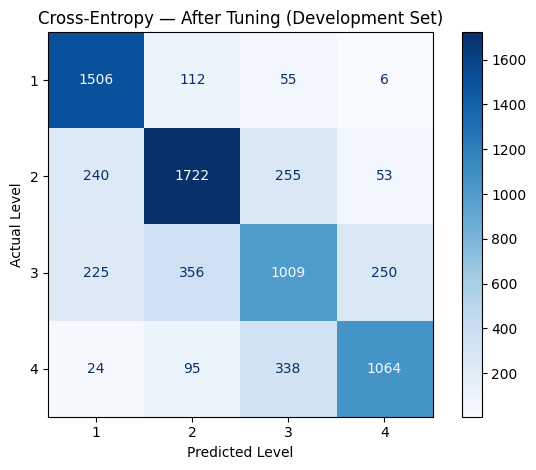

In [ ]:
ce_tuned_y_true, ce_tuned_y_pred = tuned_dev_predictions(
    cross_entropy_trainer, "Weighted Cross-Entropy"
)
plot_development_confusion_matrix(
    ce_tuned_y_true, ce_tuned_y_pred,
    "Cross-Entropy — After Tuning (Development Set)"
)

## 6. Model 2 — AraBERT with CORAL Ordinal Regression

### 6.1 Model Overview and Justification

CORAL (Consistent Rank Logits) is an ordinal regression approach designed for classification tasks where labels have a meaningful order. Unlike conventional Cross-Entropy classification, CORAL explicitly considers the ordering of classes by transforming the prediction task into a set of rank-consistent binary decisions [Cao et al., 2020].

CORAL was selected because Arabic readability levels are inherently ordered, and predicting a neighboring level is less severe than predicting a distant one. Its relevance is further supported by Nazzal (2025), who applied AraBERT with CORAL to the BAREC Shared Task for fine-grained Arabic readability assessment.

Therefore, this experiment investigates whether incorporating ordinal relationships improves prediction performance, particularly in terms of QWK and ordinal error metrics.

### 6.2 Training and Development Evaluation

In [ ]:
class AraBERTCoral(nn.Module):
    def __init__(self, model_name, num_labels, dropout_probability=0.1):
        super().__init__()
        self.num_labels = num_labels
        self.config = AutoConfig.from_pretrained(model_name)
        self.encoder = AutoModel.from_pretrained(model_name, config=self.config)
        self.dropout = nn.Dropout(dropout_probability)
        self.coral_layer = CoralLayer(
            size_in=self.config.hidden_size,
            num_classes=num_labels,
        )

    @staticmethod
    def labels_to_levels(labels, num_labels):
        boundaries = torch.arange(
            num_labels - 1,
            device=labels.device,
        ).unsqueeze(0)
        return (labels.unsqueeze(1) > boundaries).float()

    def forward(self, input_ids=None, attention_mask=None, token_type_ids=None, labels=None):
        encoder_inputs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
        }
        if token_type_ids is not None:
            encoder_inputs["token_type_ids"] = token_type_ids

        encoder_outputs = self.encoder(**encoder_inputs)
        cls_representation = self.dropout(encoder_outputs.last_hidden_state[:, 0, :])
        logits = self.coral_layer(cls_representation)

        loss = None
        if labels is not None:
            levels = self.labels_to_levels(labels, self.num_labels)
            loss = coral_loss(logits, levels)

        return SequenceClassifierOutput(loss=loss, logits=logits)

set_seed(SEED)
coral_model = AraBERTCoral(MODEL_NAME, NUM_LABELS)

coral_trainer = Trainer(
    model=coral_model,
    args=make_training_args("./results_coral"),
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_coral_metrics,
)

coral_trainer.train()
coral_validation_metrics = coral_trainer.evaluate()
coral_validation_metrics


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One
1,1.425500,1.360756,0.496990,0.451974,0.706776,0.621204,0.935615,0.890698
2,1.265200,1.355933,0.519425,0.475293,0.727144,0.582900,0.897405,0.906566
3,1.179500,1.405462,0.493844,0.448351,0.712787,0.616553,0.925324,0.899042


{'eval_loss': 1.355932593345642,
 'eval_accuracy': 0.5194254445964432,
 'eval_macro_f1': 0.4752926474383691,
 'eval_qwk': 0.7271443892359966,
 'eval_mae': 0.5829001367989056,
 'eval_rmse': 0.8974046786811073,
 'eval_within_one': 0.9065663474692203,
 'eval_runtime': 5.1529,
 'eval_samples_per_second': 1418.623,
 'eval_steps_per_second': 44.441,
 'epoch': 3.0}


### 6.3 Initial Training Findings

The AraBERT + CORAL model was trained for three epochs using the shared training configuration.

**Best Development Results (Epoch 2):**

| Metric | Result |
|---|---:|
| Accuracy | 0.5194 |
| Macro-F1 | 0.4753 |
| QWK | 0.7271 |
| MAE | 0.5829 |
| RMSE | 0.8974 |
| Within-One Accuracy | 0.9066 |

**Interpretation:**

- **QWK (0.7271):** Indicates that CORAL captures meaningful ordinal relationships between readability levels.
- **Accuracy (51.94%) and Macro-F1 (47.53%):** Show that exact classification remains challenging.
- **MAE (0.5829) and RMSE (0.8974):** Reflect the magnitude of ordinal prediction errors.
- **Within-One Accuracy (90.66%):** Most predictions were correct or within one neighboring readability level.

**Training Observation:**

Validation QWK improved from 0.7068 to 0.7271 at Epoch 2, before decreasing to 0.7128 at Epoch 3. Although training loss continued decreasing, validation loss increased during the final epoch, suggesting possible overfitting.

**Conclusion:**

Epoch 2 achieved the highest development QWK and was retained as the best checkpoint. Hyperparameter tuning will investigate whether alternative fine-tuning settings can improve CORAL's ordinal classification performance.


### 6.4 Initial Training Confusion Matrix

The confusion matrix presents CORAL predictions from the initial training on the development set. The diagonal shows correct readability levels; errors near or far from the diagonal indicate adjacent or more distant ordinal misclassifications.

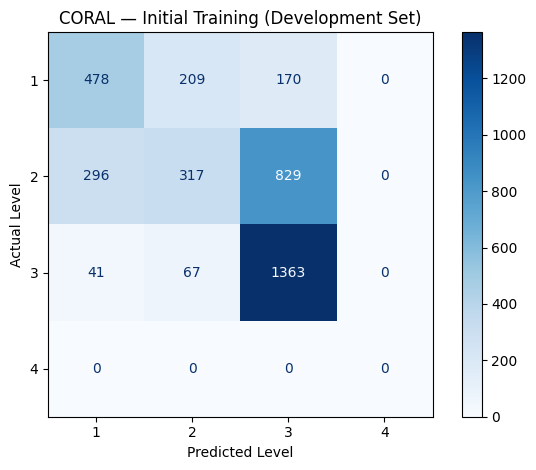

In [ ]:

# 6.4 CORAL — Initial Training Confusion Matrix

from torch.utils.data import DataLoader
from pathlib import Path
from safetensors.torch import load_file
import torch
import numpy as np

# Load the best checkpoint from initial training
checkpoint = find_initial_checkpoint("./results_coral")

model = AraBERTCoral(MODEL_NAME, NUM_LABELS)

safe_path = checkpoint / "model.safetensors"
bin_path = checkpoint / "pytorch_model.bin"

if safe_path.exists():
    weights = load_file(str(safe_path))
else:
    weights = torch.load(
        bin_path, map_location="cpu", weights_only=True
    )

model.load_state_dict(weights)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model.to(device)
model.eval()

# Prepare development dataset
loader = DataLoader(
    val_ds,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

coral_initial_y_true = []
coral_initial_y_pred = []

# Generate predictions without Trainer
with torch.inference_mode():
    for batch in loader:
        labels = batch.pop("labels")

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
        }

        logits = model(**inputs).logits

        predictions = (
            (torch.sigmoid(logits) > 0.5)
            .sum(dim=1)
        )

        coral_initial_y_true.extend(
            labels.cpu().numpy()
        )
        coral_initial_y_pred.extend(
            predictions.cpu().numpy()
        )

# Convert predictions to arrays
coral_initial_y_true = np.array(coral_initial_y_true)
coral_initial_y_pred = np.array(coral_initial_y_pred)

# Plot confusion matrix
plot_development_confusion_matrix(
    coral_initial_y_true,
    coral_initial_y_pred,
    "CORAL — Initial Training (Development Set)"
)

# Release memory
model.to("cpu")
del model

if torch.cuda.is_available():
    torch.cuda.empty_cache()


### 6.5 Hyperparameter Tuning Using Grid Search

A computationally constrained grid search is conducted to optimize the AraBERT + CORAL model.

#### Search Space and Justification

The search space is informed by the BERT fine-tuning recommendations [2] and the ZAI system, which applied AraBERT with CORAL to the BAREC Shared Task [6].

| Hyperparameter | Search Values | Justification |
|---|---|---|
| Learning Rate | 2e-5, 3e-5 | 2e-5 was used by ZAI [6], while both values are supported by BERT fine-tuning recommendations [2]. |
| Number of Epochs | 2, 3 | Both values fall within the recommended BERT fine-tuning range [2]. |
| Batch Size | 16 | Consistent with the ZAI configuration [6]. |

The remaining training settings are kept unchanged.

The grid consists of four configurations. The previously evaluated configuration (2e-5, 3 epochs) is reused, while three additional configurations are trained independently.

#### Model Selection

All configurations are evaluated on the development set using QWK. The configuration achieving the highest development QWK is selected for subsequent comparison with the other deep learning models.

The test set remains reserved for final evaluation.

In [ ]:
import gc
from itertools import product
from pathlib import Path

# Reuse initial CORAL results
coral_initial_metrics = dict(coral_validation_metrics)

best_coral_qwk = float(coral_initial_metrics["eval_qwk"])
best_coral_config = (LEARNING_RATE, NUM_EPOCHS)
best_coral_metrics = dict(coral_initial_metrics)

best_coral_path = Path("/content/coral_grid_best.pt")

def coral_result_row(lr, epochs, metrics, source):
    return {
        "learning_rate": lr,
        "epochs": epochs,
        "accuracy": metrics["eval_accuracy"],
        "macro_f1": metrics["eval_macro_f1"],
        "qwk": metrics["eval_qwk"],
        "mae": metrics["eval_mae"],
        "rmse": metrics["eval_rmse"],
        "within_one": metrics["eval_within_one"],
        "source": source
    }

coral_grid_results = [
    coral_result_row(
        LEARNING_RATE,
        NUM_EPOCHS,
        coral_initial_metrics,
        "Initial training"
    )
]

# Release GPU memory
coral_trainer.model.to("cpu")
coral_trainer.optimizer = None
coral_trainer.lr_scheduler = None

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Define the 2 x 2 grid
coral_grid = list(product(
    [2e-5, 3e-5],
    [2, 3]
))

for lr, epochs in coral_grid:

    # Skip completed initial configuration
    if (lr, epochs) == (LEARNING_RATE, NUM_EPOCHS):
        continue

    print(f"\nCORAL Training: LR={lr}, Epochs={epochs}")

    set_seed(SEED)

    args = make_training_args(
        f"/content/coral_grid_lr{lr}_ep{epochs}"
    )

    args.learning_rate = lr
    args.num_train_epochs = epochs
    args.warmup_steps = round(
        WARMUP_FRACTION * updates_per_epoch * epochs
    )

    # Initialize a fresh CORAL model
    model = AraBERTCoral(
        MODEL_NAME,
        NUM_LABELS
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_coral_metrics
    )

    trainer.train()
    metrics = trainer.evaluate()

    coral_grid_results.append(
        coral_result_row(
            lr, epochs, metrics, "Grid search"
        )
    )

    # Save the best CORAL weights
    if metrics["eval_qwk"] > best_coral_qwk:
        best_coral_qwk = float(metrics["eval_qwk"])
        best_coral_config = (lr, epochs)
        best_coral_metrics = dict(metrics)

        torch.save(
            {
                k: v.detach().cpu()
                for k, v in trainer.model.state_dict().items()
            },
            best_coral_path
        )

    # Free memory between trials
    trainer.optimizer = None
    trainer.lr_scheduler = None
    trainer.model.to("cpu")

    del trainer, model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Display results
coral_grid_df = pd.DataFrame(
    coral_grid_results
).sort_values(
    "qwk", ascending=False
).reset_index(drop=True)

display(coral_grid_df)

# Restore the best configuration
SELECTED_CORAL_LR, SELECTED_CORAL_EPOCHS = best_coral_config

if best_coral_config != (LEARNING_RATE, NUM_EPOCHS):

    del coral_trainer, coral_model
    gc.collect()

    coral_model = AraBERTCoral(
        MODEL_NAME,
        NUM_LABELS
    )

    coral_model.load_state_dict(
        torch.load(
            best_coral_path,
            map_location="cpu",
            weights_only=True
        )
    )

    coral_trainer = Trainer(
        model=coral_model,
        args=make_training_args(
            "/content/coral_grid_selected"
        ),
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_coral_metrics
    )

else:
    coral_trainer.model.to(DEVICE)

coral_validation_metrics = best_coral_metrics

print("\nBest CORAL Configuration:", best_coral_config)
print("Best Validation QWK:", round(best_coral_qwk, 6))



CORAL Training: LR=2e-05, Epochs=2


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One
1,1.414700,1.350818,0.495759,0.451395,0.705902,0.622025,0.936200,0.891655
2,1.262900,1.348291,0.498495,0.450822,0.712312,0.613953,0.926580,0.897401



CORAL Training: LR=3e-05, Epochs=2


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One
1,1.406200,1.336341,0.501231,0.457791,0.714819,0.609713,0.920432,0.896854
2,1.235000,1.338758,0.496580,0.449885,0.718646,0.609166,0.914767,0.902326



CORAL Training: LR=3e-05, Epochs=3


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One
1,1.415700,1.351507,0.493981,0.445549,0.712931,0.618468,0.927391,0.895896
2,1.239400,1.327868,0.523119,0.478264,0.733232,0.575650,0.887672,0.908618
3,1.133700,1.418978,0.492066,0.445607,0.713215,0.618194,0.925472,0.898632


,learning_rate,epochs,accuracy,macro_f1,qwk,mae,rmse,within_one,source
0,0.00003,3,0.523119,0.478264,0.733232,0.575650,0.887672,0.908618,Grid search
1,0.00002,3,0.519425,0.475293,0.727144,0.582900,0.897405,0.906566,Initial training
2,0.00003,2,0.496580,0.449885,0.718646,0.609166,0.914767,0.902326,Grid search
3,0.00002,2,0.498495,0.450822,0.712312,0.613953,0.926580,0.897401,Grid search



Best CORAL Configuration: (3e-05, 3)
Best Validation QWK: 0.733232


### 6.6 Hyperparameter Tuning Findings

The grid search evaluated four configurations of AraBERT + CORAL by varying the learning rate and number of training epochs.

**Performance Comparison:**

| Metric | Initial Training | After Tuning |
|---|---|---|
| Learning Rate | 2e-5 | 3e-5 |
| Configured Epochs | 3 | 3 |
| Accuracy | 0.5194 | 0.5231 |
| Macro-F1 | 0.4753 | 0.4783 |
| QWK | 0.7271 | 0.7332 |
| MAE | 0.5829 | 0.5757 |
| RMSE | 0.8974 | 0.8877 |
| Within-One | 0.9066 | 0.9086 |

**Interpretation:**

- Increasing the learning rate from 2e-5 to 3e-5 improved QWK from 0.7271 to 0.7332, suggesting that the higher learning rate may have supported more effective fine-tuning.
- Accuracy and Macro-F1 increased slightly, while MAE and RMSE decreased, indicating improvements in both exact classification and ordinal prediction errors.
- The best configuration was scheduled for three epochs, but its highest QWK occurred at Epoch 2. Performance declined at Epoch 3, suggesting possible overfitting.

**Conclusion:**

Grid search identified **3e-5 with a three-epoch training schedule** as the best configuration, achieving a QWK improvement of approximately 0.0061. The Epoch 2 checkpoint was retained for subsequent model comparison. Although the improvement is modest, the remaining evaluation metrics also improved.

### 6.7 Tuned Model Confusion Matrix

This matrix shows the CORAL checkpoint selected by development QWK after grid search. Comparison with Section 6.4 illustrates how tuning affected errors among the four ordered readability levels.

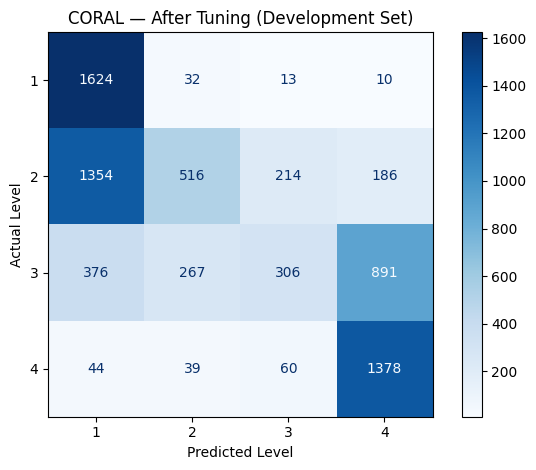

In [ ]:
coral_tuned_y_true, coral_tuned_y_pred = tuned_dev_predictions(
    coral_trainer, "CORAL"
)
plot_development_confusion_matrix(
    coral_tuned_y_true, coral_tuned_y_pred,
    "CORAL — After Tuning (Development Set)"
)

## 7. Model 3 — AraBERTv0.2 + MSE Regression

### 7.1 Model Rationale

MSE predicts a **single continuous readability score** and penalizes larger numerical errors more strongly. For the same four ordered levels, predictions are rounded and clipped to indices `0–3` before classification evaluation. Regression-oriented BAREC approaches motivate this comparison [5], [7].

### 7.2 Training and Development Evaluation

In [ ]:
class MSERegressionTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels").float()
        outputs = model(**inputs)
        scores = outputs.logits.squeeze(-1)
        loss = nn.MSELoss()(scores, labels)
        return (loss, outputs) if return_outputs else loss

set_seed(SEED)
mse_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=1,
    problem_type="regression",
)

mse_trainer = MSERegressionTrainer(
    model=mse_model,
    args=make_training_args("./results_mse_regression"),
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_mse_metrics,
)

mse_trainer.train()
mse_validation_metrics = mse_trainer.evaluate()
mse_validation_metrics


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One,Raw Mae,Raw Rmse
1,0.549300,0.448651,0.644733,0.645273,0.775272,0.399726,0.700791,0.956772,0.489418,0.669814
2,0.333400,0.376722,0.672640,0.676274,0.790595,0.367579,0.671585,0.961286,0.433425,0.613776
3,0.259700,0.396079,0.681122,0.680496,0.788283,0.365116,0.678475,0.955130,0.419246,0.629348


{'eval_loss': 0.3767215311527252,
 'eval_accuracy': 0.672640218878249,
 'eval_macro_f1': 0.6762741923011882,
 'eval_qwk': 0.7905945358443751,
 'eval_mae': 0.36757865937072504,
 'eval_rmse': 0.6715846869844976,
 'eval_within_one': 0.9612859097127223,
 'eval_raw_mae': 0.43342453241348267,
 'eval_raw_rmse': 0.6137764504709554,
 'eval_runtime': 5.1535,
 'eval_samples_per_second': 1418.465,
 'eval_steps_per_second': 44.436,
 'epoch': 3.0}


### 7.3 Initial Training Findings

The AraBERT + MSE Regression model was trained for three epochs using the shared training configuration.

**Best Development Results (Epoch 2):**

| Metric | Result |
|---|---:|
| Accuracy | 0.6726 |
| Macro-F1 | 0.6763 |
| QWK | 0.7906 |
| MAE | 0.3676 |
| RMSE | 0.6716 |
| Within-One Accuracy | 0.9613 |
| Raw MAE | 0.4334 |
| Raw RMSE | 0.6138 |

**Interpretation:**

- **QWK (0.7906):** Indicates strong ordinal agreement, demonstrating the model's ability to account for differences between readability levels.
- **Accuracy (67.26%) and Macro-F1 (67.63%):** Show reasonable exact classification performance across the four readability levels.
- **MAE (0.3676) and RMSE (0.6716):** Indicate relatively small ordinal prediction errors, with RMSE reflecting greater sensitivity to larger deviations.
- **Within-One Accuracy (96.13%):** Most predictions were correct or within one adjacent readability level.
- **Raw MAE (0.4334) and Raw RMSE (0.6138):** Measure regression errors before rounding continuous predictions into discrete readability levels.

**Training Observation:**

Training loss decreased consistently from 0.5493 to 0.2597. Validation loss reached its minimum at Epoch 2 (0.3767), where QWK was highest (0.7906). Although Accuracy increased slightly at Epoch 3, QWK decreased to 0.7883 and validation loss increased, suggesting possible overfitting.

**Conclusion:**

Epoch 2 was selected as the best checkpoint based on development QWK. The results suggest that MSE Regression is effective at preserving ordinal relationships. Hyperparameter tuning will investigate whether alternative training configurations can further improve its performance.


### 7.4 Initial Training Confusion Matrix

This confusion matrix presents predictions from the initial MSE Regression checkpoint on the development set, after rounding and clipping continuous scores to the four ordered readability levels.

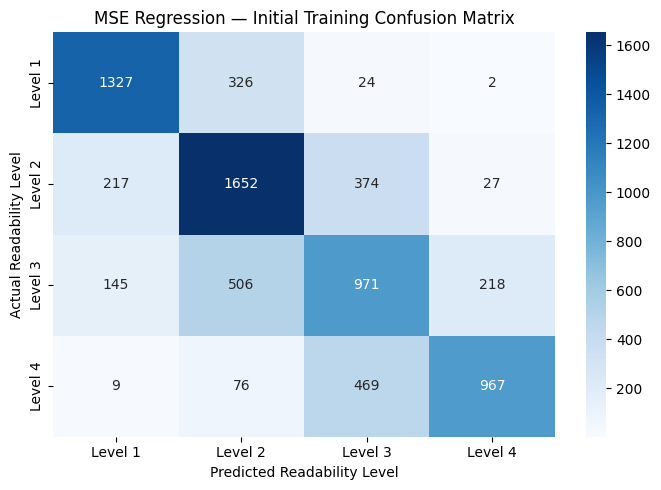

In [ ]:
# MSE Regression — Initial Training Confusion Matrix

from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch

# Use the best initial checkpoint selected by Validation QWK
model = mse_trainer.model
model.eval()
device = next(model.parameters()).device

# Prepare development dataset
loader = DataLoader(
    val_ds,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

mse_initial_y_true = []
mse_initial_y_pred = []

# Generate predictions without Trainer
with torch.inference_mode():
    for batch in loader:
        labels = batch.pop("labels")

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
        }

        # Continuous regression predictions
        raw_scores = model(**inputs).logits.squeeze(-1)

        # Convert scores to ordinal labels (0-3)
        predictions = torch.clamp(
            torch.round(raw_scores), 0, NUM_LABELS - 1
        ).long()

        mse_initial_y_true.extend(labels.cpu().numpy())
        mse_initial_y_pred.extend(predictions.cpu().numpy())

# Convert labels from 0-3 to 1-4
y_true = np.array(mse_initial_y_true) + 1
y_pred = np.array(mse_initial_y_pred) + 1

# Compute confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=[1, 2, 3, 4]
)

# Plot
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Level 1", "Level 2", "Level 3", "Level 4"],
    yticklabels=["Level 1", "Level 2", "Level 3", "Level 4"]
)

plt.title("MSE Regression — Initial Training Confusion Matrix")
plt.xlabel("Predicted Readability Level")
plt.ylabel("Actual Readability Level")
plt.tight_layout()
plt.show()


### 7.5 Hyperparameter Tuning Using Grid Search

A computationally constrained grid search evaluates MSE Regression using the same four combinations tested for the other AraBERT-based approaches, enabling a consistent comparison of training settings.

#### Search Space and Justification

| Hyperparameter | Values | Justification |
|---|---|---|
| Learning rate | `2e-5`, `3e-5` | Within the BERT fine-tuning search range [2]. |
| Number of epochs | `2`, `3` | Both fall within the BERT fine-tuning range [2]. |
| Batch size | `16` (fixed) | Maintains the common experimental setting, supported by BERT fine-tuning practice [2]. |

Weight decay, gradient accumulation, and warm-up fraction remain unchanged. The previously completed (`2e-5`, 3 epochs) run is reused, so only three additional configurations are trained. Each independently initialized model is evaluated using **development QWK**, and the best checkpoint is retained. This restricted search is motivated by computational cost and does not establish global optimality. The test set is not accessed during tuning [3], [7].

In [ ]:
from itertools import product
from pathlib import Path
import gc
import shutil

# Preserve initial training results before tuning
mse_initial_metrics = dict(mse_validation_metrics)

mse_best_qwk = float(mse_initial_metrics["eval_qwk"])
mse_best_metrics = dict(mse_initial_metrics)
mse_best_config = (LEARNING_RATE, NUM_EPOCHS)

mse_best_qwk = float(mse_initial_metrics["eval_qwk"])
mse_best_metrics = dict(mse_initial_metrics)
mse_best_config = (LEARNING_RATE, NUM_EPOCHS)
mse_best_dir = Path("/content/mse_grid_best")

def mse_grid_row(lr, epochs, metrics, source):
    return {
        "learning_rate": lr,
        "epochs": epochs,
        **{metric: float(metrics[f"eval_{metric}"])
           for metric in ["accuracy", "macro_f1", "qwk", "mae", "rmse", "within_one"]},
        "source": source,
    }

mse_grid_rows = [mse_grid_row(LEARNING_RATE, NUM_EPOCHS, mse_initial_metrics, "Initial training")]

# Release the initial Trainer's GPU memory before sequential experiments.
mse_trainer.model.to("cpu")
mse_trainer.optimizer = None
mse_trainer.lr_scheduler = None
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

for lr, epochs in product([2e-5, 3e-5], [2, 3]):
    if (lr, epochs) == (LEARNING_RATE, NUM_EPOCHS):
        continue

    print(f"\nMSE Training: LR={lr}, Epochs={epochs}")
    set_seed(SEED)

    args = make_training_args(f"/content/mse_grid_lr{lr}_ep{epochs}")
    args.learning_rate = lr
    args.num_train_epochs = epochs
    args.warmup_steps = round(WARMUP_FRACTION * updates_per_epoch * epochs)

    candidate = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=1, problem_type="regression"
    )
    trial_trainer = MSERegressionTrainer(
        model=candidate,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_mse_metrics,
    )

    trial_trainer.train()
    scores = trial_trainer.evaluate()
    mse_grid_rows.append(mse_grid_row(lr, epochs, scores, "Grid search"))

    if float(scores["eval_qwk"]) > mse_best_qwk:
        mse_best_qwk = float(scores["eval_qwk"])
        mse_best_config = (lr, epochs)
        mse_best_metrics = dict(scores)
        shutil.rmtree(mse_best_dir, ignore_errors=True)
        trial_trainer.model.save_pretrained(str(mse_best_dir), safe_serialization=True)

    trial_trainer.optimizer = None
    trial_trainer.lr_scheduler = None
    trial_trainer.model.to("cpu")
    del trial_trainer, candidate
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

mse_grid_df = pd.DataFrame(mse_grid_rows).sort_values(
    "qwk", ascending=False
).reset_index(drop=True)
display(mse_grid_df.round(4))

SELECTED_MSE_LR, SELECTED_MSE_EPOCHS = mse_best_config

if mse_best_config != (LEARNING_RATE, NUM_EPOCHS):
    del mse_trainer, mse_model
    gc.collect()

    mse_model = AutoModelForSequenceClassification.from_pretrained(str(mse_best_dir))
    mse_selected_args = make_training_args("/content/mse_grid_selected")
    mse_selected_args.learning_rate = SELECTED_MSE_LR
    mse_selected_args.num_train_epochs = SELECTED_MSE_EPOCHS
    mse_selected_args.warmup_steps = round(
        WARMUP_FRACTION * updates_per_epoch * SELECTED_MSE_EPOCHS
    )
    mse_trainer = MSERegressionTrainer(
        model=mse_model,
        args=mse_selected_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_mse_metrics,
    )
else:
    mse_trainer.model.to(DEVICE)

mse_validation_metrics = mse_best_metrics
print("Best MSE Configuration:", mse_best_config)
print("Best Development QWK:", round(mse_best_qwk, 6))


MSE Training: LR=2e-05, Epochs=2


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One,Raw Mae,Raw Rmse
1,0.525300,0.415002,0.649932,0.652645,0.779339,0.389330,0.685196,0.961560,0.473527,0.644207
2,0.328900,0.386436,0.669220,0.669249,0.785140,0.371683,0.675039,0.960192,0.432782,0.621640



MSE Training: LR=3e-05, Epochs=2


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...


MSE Training: LR=3e-05, Epochs=3


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Qwk,Mae,Rmse,Within One,Raw Mae,Raw Rmse
1,0.530700,0.451808,0.642681,0.637486,0.767382,0.408071,0.716524,0.951163,0.477760,0.672167
2,0.323100,0.372061,0.678933,0.682139,0.792467,0.362107,0.668931,0.960602,0.419509,0.609968
3,0.235100,0.393106,0.686867,0.684677,0.787831,0.361970,0.680991,0.953215,0.399906,0.626981


,learning_rate,epochs,accuracy,macro_f1,qwk,mae,rmse,within_one,source
0,0.0,3,0.6789,0.6821,0.7925,0.3621,0.6689,0.9606,Grid search
1,0.0,3,0.6726,0.6763,0.7906,0.3676,0.6716,0.9613,Initial training
2,0.0,2,0.6769,0.6774,0.7881,0.3662,0.6742,0.9580,Grid search
3,0.0,2,0.6692,0.6692,0.7851,0.3717,0.6750,0.9602,Grid search


Best MSE Configuration: (3e-05, 3)
Best Development QWK: 0.792467



### 7.6 Hyperparameter Tuning Findings

The grid search evaluated four configurations of AraBERT + MSE Regression by varying the learning rate and number of training epochs.

**Performance Comparison:**

| Metric | Initial Training | After Tuning |
|---|---|---|
| Learning Rate | 2e-5 | 3e-5 |
| Configured Epochs | 3 | 3 |
| Accuracy | 0.6726 | 0.6789 |
| Macro-F1 | 0.6763 | 0.6821 |
| QWK | 0.7906 | 0.7925 |
| MAE | 0.3676 | 0.3621 |
| RMSE | 0.6716 | 0.6689 |
| Within-One | 0.9613 | 0.9606 |
| Raw MAE | 0.4334 | 0.4195 |
| Raw RMSE | 0.6138 | 0.6100 |

**Interpretation:**

- Increasing the learning rate from 2e-5 to 3e-5 improved QWK from 0.7906 to 0.7925, suggesting that the higher learning rate may have supported more effective fine-tuning.
- Accuracy and Macro-F1 increased, while MAE, RMSE, and raw regression errors decreased, indicating modest improvements in classification and ordinal prediction performance.
- Within-One Accuracy decreased slightly from 96.13% to 96.06%. However, the tuned configuration achieved a higher QWK, which remains the primary selection metric.
- The best configuration was scheduled for three epochs, but its highest QWK occurred at Epoch 2. The increase in validation loss and decrease in QWK at Epoch 3 suggest possible overfitting.

**Conclusion:**

Grid search identified **3e-5 with a three-epoch training schedule** as the best configuration, achieving a modest QWK improvement of approximately 0.0019. The Epoch 2 checkpoint was retained for subsequent model comparison.

Although most evaluation metrics improved, the difference is small and does not establish a statistically significant improvement from a single run.


### 7.7 Tuned Model Confusion Matrix

This confusion matrix shows the development predictions of the MSE Regression configuration selected after grid search. It can be compared with Section 7.4 to inspect any changes in adjacent and distant classification errors.

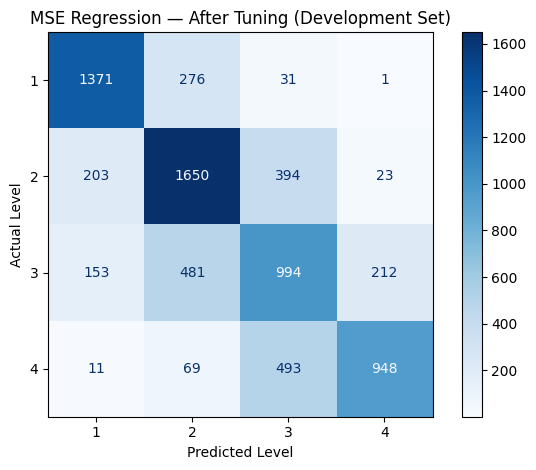

In [ ]:
mse_tuned_y_true, mse_tuned_y_pred = tuned_dev_predictions(
    mse_trainer, "MSE Regression"
)
plot_development_confusion_matrix(
    mse_tuned_y_true, mse_tuned_y_pred,
    "MSE Regression — After Tuning (Development Set)"
)

## 8. Development Results and Model Selection

This section compares the three AraBERT-based models before and after hyperparameter tuning using the development set.

The comparison considers exact classification performance and ordinal prediction errors. QWK is used as the primary selection criterion, consistent with the BAREC evaluation methodology.

Both initial and tuned results are presented to assess the effect of hyperparameter optimization and support the final model selection.


In [ ]:
# 8. Development Results and Model Selection

metric_cols = [
    "accuracy", "macro_f1", "qwk",
    "mae", "rmse", "within_one"
]

# Results from the completed Grid Search experiments
model_results = {
    "Weighted Cross-Entropy": ce_grid_results,
    "CORAL": coral_grid_df,
    "MSE Regression": mse_grid_df
}

before_rows = []
after_rows = []

for name, grid_df in model_results.items():

    # Retrieve the initial training configuration
    initial = grid_df[
        grid_df["source"] == "Initial training"
    ].iloc[0]

    # Retrieve the best configuration by Development QWK
    tuned = grid_df.loc[grid_df["qwk"].idxmax()]

    for row, results in [
        (initial, before_rows),
        (tuned, after_rows)
    ]:
        results.append({
            "model": name,
            "learning_rate": float(row["learning_rate"]),
            "epochs": int(row["epochs"]),
            **{
                metric: float(row[metric])
                for metric in metric_cols
            }
        })

# Create comparison tables
validation_before = pd.DataFrame(
    before_rows
).sort_values(
    "qwk", ascending=False
).reset_index(drop=True)

validation_comparison = pd.DataFrame(
    after_rows
).sort_values(
    "qwk", ascending=False
).reset_index(drop=True)

# Display formatting
formats = {
    "learning_rate": "{:.0e}",
    **{metric: "{:.4f}" for metric in metric_cols}
}

print("=== Before Hyperparameter Tuning ===")
display(validation_before.style.format(formats))

print("\n=== After Hyperparameter Tuning ===")
display(validation_comparison.style.format(formats))

# Compare QWK improvement
qwk_improvement = (
    validation_comparison.set_index("model")["qwk"]
    - validation_before.set_index("model")["qwk"]
)

print("\n=== QWK Improvement ===")
display(
    qwk_improvement.rename(
        "QWK Difference"
    ).to_frame().style.format("{:+.6f}")
)

# Select highest Development QWK
best_model_name = validation_comparison.loc[0, "model"]

# Identify highest exact Accuracy separately
highest_accuracy_model = validation_comparison.loc[
    validation_comparison["accuracy"].idxmax(),
    "model"
]

print("\nSelected by QWK:", best_model_name)
print("Highest Accuracy:", highest_accuracy_model)


=== Before Hyperparameter Tuning ===


,model,learning_rate,epochs,accuracy,macro_f1,qwk,mae,rmse,within_one
0,MSE Regression,2e-05,3,0.6726,0.6763,0.7906,0.3676,0.6716,0.9613
1,Weighted Cross-Entropy,2e-05,3,0.7189,0.7151,0.7833,0.3498,0.7050,0.9363
2,CORAL,2e-05,3,0.5194,0.4753,0.7271,0.5829,0.8974,0.9066



=== After Hyperparameter Tuning ===


,model,learning_rate,epochs,accuracy,macro_f1,qwk,mae,rmse,within_one
0,MSE Regression,3e-05,3,0.6789,0.6821,0.7925,0.3621,0.6689,0.9606
1,Weighted Cross-Entropy,3e-05,3,0.7252,0.7221,0.7876,0.3416,0.6952,0.9373
2,CORAL,3e-05,3,0.5231,0.4783,0.7332,0.5756,0.8877,0.9086



=== QWK Improvement ===


,QWK Difference
model,
MSE Regression,+0.001873
Weighted Cross-Entropy,+0.004367
CORAL,+0.006088



Selected by QWK: MSE Regression
Highest Accuracy: Weighted Cross-Entropy


## 9. Final Test Evaluation

After selecting the development-QWK winner, evaluate **only that model** on the previously untouched test split. Do not revise the model choice using test scores.

In [ ]:
model_registry = {
    "Weighted Cross-Entropy": (cross_entropy_trainer, compute_cross_entropy_metrics),
    "CORAL": (coral_trainer, compute_coral_metrics),
    "MSE Regression": (mse_trainer, compute_mse_metrics),
}

best_trainer, _ = model_registry[best_model_name]
best_trainer.model.to(DEVICE)
test_output = best_trainer.predict(test_ds)
test_metrics = test_output.metrics

if best_model_name == "Weighted Cross-Entropy":
    test_predictions = np.argmax(unpack_logits(test_output.predictions), axis=-1)
elif best_model_name == "CORAL":
    test_predictions = coral_logits_to_labels(unpack_logits(test_output.predictions))
else:
    test_predictions = regression_outputs_to_labels(unpack_logits(test_output.predictions))

test_labels = np.asarray(test_output.label_ids, dtype=int)

test_summary = pd.DataFrame([{
    "selected_model": best_model_name,
    "accuracy": test_metrics["test_accuracy"],
    "macro_f1": test_metrics["test_macro_f1"],
    "qwk": test_metrics["test_qwk"],
    "mae": test_metrics["test_mae"],
    "rmse": test_metrics["test_rmse"],
    "within_one": test_metrics["test_within_one"],
}])
display(test_summary)


,selected_model,accuracy,macro_f1,qwk,mae,rmse,within_one
0,MSE Regression,0.678973,0.69127,0.791547,0.355202,0.652283,0.966786


## 10. Confusion Matrix and Classification Report

Matrix rows are the true readability level and columns are the predicted level (`1–4`). Errors close to the diagonal are less severe than errors between distant levels.

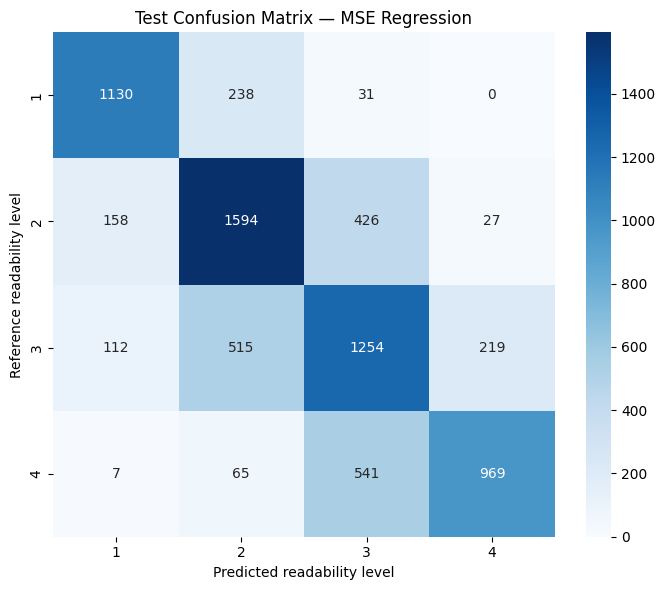

              precision    recall  f1-score   support

     Level 1     0.8031    0.8077    0.8054      1399
     Level 2     0.6609    0.7229    0.6905      2205
     Level 3     0.5568    0.5971    0.5763      2100
     Level 4     0.7975    0.6125    0.6929      1582

    accuracy                         0.6790      7286
   macro avg     0.7046    0.6851    0.6913      7286
weighted avg     0.6879    0.6790    0.6802      7286



In [ ]:
human_labels = np.arange(1, NUM_LABELS + 1)
cm = confusion_matrix(test_labels + 1, test_predictions + 1, labels=human_labels)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=human_labels,
    yticklabels=human_labels,
)
plt.title(f"Test Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted readability level")
plt.ylabel("Reference readability level")
plt.tight_layout()
plt.show()

print(classification_report(
    test_labels + 1,
    test_predictions + 1,
    labels=human_labels,
    target_names=[f"Level {level}" for level in human_labels],
    digits=4,
    zero_division=0,
))


## 11. Save and Load the Selected Model

The selected **trained weights**, AraBERT tokenizer, model configuration, and metric metadata are exported together so team members can use the model **without retraining**. Weighted Cross-Entropy and MSE use the Hugging Face model format; CORAL uses the original custom head state dictionary. An independent loader script supports all three outputs.

### 11.1 Export the Selected Model

In [ ]:
import json
import os
import shutil
from pathlib import Path

SAVE_DIR = Path("/content/faseeh_best_model")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save the hyperparameters of the selected configuration, not the initial values.
SELECTED_PARAMETERS = {
    "Weighted Cross-Entropy": {"learning_rate": SELECTED_CE_LR, "epochs": SELECTED_CE_EPOCHS},
    "CORAL": {"learning_rate": SELECTED_CORAL_LR, "epochs": SELECTED_CORAL_EPOCHS},
    "MSE Regression": {"learning_rate": SELECTED_MSE_LR, "epochs": SELECTED_MSE_EPOCHS},
}[best_model_name]

# best_trainer comes from Section 9 and contains the selected checkpoint
best_trainer.model.to("cpu")
tokenizer.save_pretrained(str(SAVE_DIR))

if best_model_name == "CORAL":
    best_trainer.model.config.save_pretrained(str(SAVE_DIR))
    torch.save(best_trainer.model.state_dict(), SAVE_DIR / "coral_model_state.pt")
else:
    best_trainer.model.save_pretrained(str(SAVE_DIR), safe_serialization=True)

metadata = {
    "selected_model": best_model_name,
    "model_name": MODEL_NAME,
    "num_labels": NUM_LABELS,
    "label_index_to_level": {str(i): i + 1 for i in range(NUM_LABELS)},
    "max_length": MAX_LENGTH,
    "selection_metric": "development_qwk",
    "training_parameters": {
        "learning_rate": SELECTED_PARAMETERS["learning_rate"],
        "train_batch_size": TRAIN_BATCH_SIZE,
        "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
        "epochs": SELECTED_PARAMETERS["epochs"],
        "weight_decay": WEIGHT_DECAY,
        "warmup_fraction": WARMUP_FRACTION,
    },
    "development_comparison": validation_comparison.to_dict(orient="records"),
    "test_metrics": {
        key: float(value) for key, value in test_metrics.items()
        if isinstance(value, (int, float, np.integer, np.floating))
    },
}
with (SAVE_DIR / "experiment_metadata.json").open("w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

LOADER_SCRIPT = '"""Load the selected Faseeh readability model from its exported folder.\nRequires: torch, transformers (4.x), coral-pytorch (only if CORAL was selected).\nThis loader needs no training data or internet once the model package is available.\n"""\nfrom pathlib import Path\nimport json\nimport torch\nfrom torch import nn\nfrom transformers import AutoConfig, AutoModel, AutoModelForSequenceClassification, AutoTokenizer\nfrom transformers.modeling_outputs import SequenceClassifierOutput\n\n\nclass SavedAraBERTCoral(nn.Module):\n    """Inference equivalent of the CORAL architecture trained in the project notebook."""\n    def __init__(self, model_dir, num_labels=4):\n        super().__init__()\n        from coral_pytorch.layers import CoralLayer\n        self.num_labels = num_labels\n        self.config = AutoConfig.from_pretrained(str(model_dir), local_files_only=True)\n        self.encoder = AutoModel.from_config(self.config)\n        self.dropout = nn.Dropout(0.1)\n        self.coral_layer = CoralLayer(size_in=self.config.hidden_size, num_classes=num_labels)\n\n    def forward(self, input_ids=None, attention_mask=None, token_type_ids=None):\n        encoder_inputs = {"input_ids": input_ids, "attention_mask": attention_mask}\n        if token_type_ids is not None:\n            encoder_inputs["token_type_ids"] = token_type_ids\n        encoded = self.encoder(**encoder_inputs)\n        pooled = self.dropout(encoded.last_hidden_state[:, 0, :])\n        return SequenceClassifierOutput(logits=self.coral_layer(pooled))\n\n\ndef load_faseeh_model(model_dir, device=None):\n    model_dir = Path(model_dir)\n    with (model_dir / "experiment_metadata.json").open(encoding="utf-8") as f:\n        metadata = json.load(f)\n\n    kind = metadata["selected_model"]\n    tokenizer = AutoTokenizer.from_pretrained(str(model_dir), local_files_only=True)\n    if kind == "CORAL":\n        model = SavedAraBERTCoral(model_dir, metadata["num_labels"])\n        state = torch.load(model_dir / "coral_model_state.pt", map_location="cpu", weights_only=True)\n        model.load_state_dict(state, strict=True)\n    elif kind in ("Weighted Cross-Entropy", "MSE Regression"):\n        model = AutoModelForSequenceClassification.from_pretrained(\n            str(model_dir), local_files_only=True)\n    else:\n        raise ValueError(f"Unrecognized saved model: {kind}")\n\n    device = device or ("cuda" if torch.cuda.is_available() else "cpu")\n    model.to(device).eval()\n    return model, tokenizer, metadata\n\n\ndef predict_readability(texts, model, tokenizer, metadata):\n    """Return predictions on the project scale (1, 2, 3, 4)."""\n    single = isinstance(texts, str)\n    if single:\n        texts = [texts]\n    inputs = tokenizer(\n        texts, return_tensors="pt", truncation=True, padding=True,\n        max_length=metadata["max_length"])\n    device = next(model.parameters()).device\n    inputs = {key: val.to(device) for key, val in inputs.items()}\n    with torch.inference_mode():\n        logits = model(**inputs).logits\n    kind = metadata["selected_model"]\n    if kind == "CORAL":\n        pred = (torch.sigmoid(logits) > 0.5).sum(dim=-1)\n    elif kind == "MSE Regression":\n        pred = logits.reshape(-1).round().clamp(0, metadata["num_labels"] - 1).long()\n    else:\n        pred = logits.argmax(dim=-1)\n    levels = (pred + 1).cpu().tolist()\n    return levels[0] if single else levels\n'
(SAVE_DIR / "faseeh_loader.py").write_text(LOADER_SCRIPT, encoding="utf-8")

ARCHIVE = shutil.make_archive("/content/faseeh_best_model", "zip", root_dir=SAVE_DIR)
print("Saved model folder:", SAVE_DIR)
print("Downloadable package:", ARCHIVE)
# Optional: download model package to upload it to GitHub Releases or commit via Git LFS:
# from google.colab import files
# files.download(ARCHIVE)

Saved model folder: /content/faseeh_best_model
Downloadable package: /content/faseeh_best_model.zip


In [ ]:
from google.colab import files
files.download("/content/faseeh_best_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 11.2 Reload for Inference (No Training)

The following also works for teammates after cloning the repository and retrieving the **full model weights**. Change `MODEL_FOLDER` to the location of the exported folder. It loads whichever model actually won by development QWK; no model name is hard-coded.

In [ ]:
import sys
from pathlib import Path

MODEL_FOLDER = Path("/content/faseeh_best_model")  # Or: your GitHub-cloned models/faseeh_best_model
sys.path.insert(0, str(MODEL_FOLDER))
from faseeh_loader import load_faseeh_model, predict_readability

loaded_model, loaded_tokenizer, model_info = load_faseeh_model(MODEL_FOLDER)
print("Loaded:", model_info["selected_model"])
print("Predicted readability level:", predict_readability(
    "هذا مثال لجملة عربية.", loaded_model, loaded_tokenizer, model_info
))

Loaded: MSE Regression
Predicted readability level: 1


## 12. Final Findings

After training, use the development comparison to explain the selected model **based on QWK**, then report its test Accuracy, Macro-F1, QWK, MAE, RMSE, and Within-One Accuracy. Interpret whether mistakes are mainly adjacent readability levels using the confusion matrix. Avoid direct leaderboard comparisons against BAREC's differently defined 19- or 5-level tasks.

In [ ]:
print("Selected approach:", best_model_name)
display(validation_comparison.round(4))
display(test_summary.round(4))

Selected approach: MSE Regression


,model,learning_rate,epochs,accuracy,macro_f1,qwk,mae,rmse,within_one
0,MSE Regression,0.0,3,0.6789,0.6821,0.7925,0.3621,0.6689,0.9606
1,Weighted Cross-Entropy,0.0,3,0.7252,0.7221,0.7876,0.3416,0.6952,0.9373
2,CORAL,0.0,3,0.5231,0.4783,0.7332,0.5756,0.8877,0.9086


,selected_model,accuracy,macro_f1,qwk,mae,rmse,within_one
0,MSE Regression,0.679,0.6913,0.7915,0.3552,0.6523,0.9668


## 13. References

[1] Antoun, W., Baly, F., & Hajj, H. (2020). **AraBERT: Transformer-based Model for Arabic Language Understanding.** OSACT 2020. https://aclanthology.org/2020.osact-1.2/

[2] Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). **BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.** NAACL-HLT 2019. https://aclanthology.org/N19-1423/

[3] Elmadani, K. N., Alhafni, B., Taha, H., & Habash, N. (2025). **BAREC Shared Task 2025 on Arabic Readability Assessment.** ArabicNLP 2025. https://aclanthology.org/2025.arabicnlp-sharedtasks.34/

[4] Cao, W., Mirjalili, V., & Raschka, S. (2020). **Rank-consistent Ordinal Regression for Neural Networks with Application to Age Estimation.** Pattern Recognition Letters, 140, 325–331. https://doi.org/10.1016/j.patrec.2020.11.008

[5] Elmadani, K. N., Habash, N., & Taha-Thomure, H. (2025). **A Large and Balanced Corpus for Fine-grained Arabic Readability Assessment.** Findings of ACL 2025. https://aclanthology.org/2025.findings-acl.842/

[6] Nazzal, A. M. (2025). **ZAI at BAREC Shared Task 2025: AraBERT CORAL for Fine Grained Arabic Readability.** ArabicNLP 2025 Shared Tasks. https://aclanthology.org/2025.arabicnlp-sharedtasks.37/

[7] Trigui, S. (2025). **STBW at BAREC Shared Task 2025: AraBERT-v2 with MSE-SoftQWK Loss for Sentence-Level Arabic Readability.** ArabicNLP 2025 Shared Tasks. https://aclanthology.org/2025.arabicnlp-sharedtasks.50/



[8] M. Mosbach, M. Andriushchenko, and D. Klakow, "On the Stability of Fine-tuning BERT: Misconceptions, Explanations, and Strong Baselines," ICLR, 2021.
https://openreview.net/forum?id=nzpLWnVAyah

[9] Hugging Face, "Trainer and TrainingArguments Documentation."
https://huggingface.co/docs/transformers/main_classes/trainer

[10] Google Research, "BERT: Original Optimization Implementation."
https://github.com/google-research/bert/blob/master/optimization.py

